# 04 · Ejercicios de probabilidad clásica

Cuatro ejercicios resueltos con conjuntos: diagramas de Venn, condicionamiento en lanzamientos repetidos, un juego con dos dados y la ley de la suma de tres dados.

In [1]:
from collections import Counter
from fractions import Fraction
from itertools import product

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Circle


def P(E, Omega):
    return Fraction(len(E & Omega), len(Omega))


def P_cond(E, F):
    return Fraction(len(E & F), len(F))

## Ejercicio 1

En un salón hay $60$ alumnos: $30$ estudian francés, $35$ estudian ruso y $5$ estudian ambos idiomas. Dibuja un diagrama de Venn y calcula la probabilidad de que un alumno elegido al azar estudie **solamente** francés.

**Solución.** Sean $F$ y $R$ los conjuntos de alumnos de francés y de ruso. Entonces $\#(F\setminus R)=30-5=25$, $\#(R\setminus F)=35-5=30$ y $\#(F\cup R)^c=60-(30+35-5)=0$. Por lo tanto

$$\mathbb{P}(F\setminus R)=\frac{25}{60}=\frac{5}{12}.$$

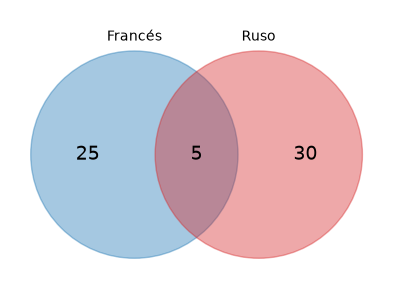

P(solo francés) = 5/12


In [2]:
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.add_patch(Circle((-0.6, 0), 1, alpha=0.4, color="tab:blue"))
ax.add_patch(Circle((0.6, 0), 1, alpha=0.4, color="tab:red"))
for x, texto in [(-1.05, "25"), (0, "5"), (1.05, "30")]:
    ax.text(x, 0, texto, ha="center", va="center", fontsize=14)
ax.text(-0.6, 1.1, "Francés", ha="center")
ax.text(0.6, 1.1, "Ruso", ha="center")
ax.set_xlim(-1.8, 1.8)
ax.set_ylim(-1.2, 1.4)
ax.set_aspect("equal")
ax.axis("off")
plt.show()

print("P(solo francés) =", Fraction(30 - 5, 60))

## Ejercicio 2

Se lanza un dado tres veces.

1. Describe el espacio muestral.
2. Calcula la probabilidad de obtener $1$ en el primer lanzamiento.
3. Calcula la probabilidad de que los tres resultados sean pares dado que el primero fue $2$.
4. ¿Es el evento «el segundo resultado es par» independiente del evento «el primer resultado es $1$»?

**Solución.** $\Omega=\{1,\dots,6\}^3$, con $\#\Omega=216$.

In [3]:
Omega = set(product(range(1, 7), repeat=3))
E1 = {w for w in Omega if w[0] == 1}
E2 = {w for w in Omega if w[0] == 2}
tres_pares = {w for w in Omega if all(x % 2 == 0 for x in w)}
segundo_par = {w for w in Omega if w[1] % 2 == 0}

print("#Ω =", len(Omega))
print("P(E1) =", P(E1, Omega))
print("P(tres pares | primero = 2) =", P_cond(tres_pares, E2))
print("¿independientes?", P(segundo_par & E1, Omega) == P(segundo_par, Omega) * P(E1, Omega))

#Ω = 216
P(E1) = 1/6
P(tres pares | primero = 2) = 1/4
¿independientes? True


Dado que el primer resultado ya es par, falta que los otros dos lo sean: $\mathbb{P}=\frac12\cdot\frac12=\frac14$. Los lanzamientos son independientes, de modo que cualquier evento que dependa solo del segundo lanzamiento es independiente de cualquiera que dependa solo del primero.

## Ejercicio 3

Alicia y Karla lanzan dos dados justos.

- Si la suma es par, Alicia gana la cara máxima y Karla pierde la cara mínima.
- Si la suma es impar, Karla gana $\$5$ y Alicia pierde $\$3$.

¿Quién tiene mayor ganancia esperada? ¿Con qué probabilidad la ganancia de Alicia supera a la de Karla?

**Solución.** Escribimos la ganancia de cada jugadora como una variable aleatoria sobre $\Omega=\{1,\dots,6\}^2$:

$$G_A(i,j)=\begin{cases}\max(i,j)& i+j \text{ par}\\ -3 & i+j\text{ impar}\end{cases}\qquad G_K(i,j)=\begin{cases}-\min(i,j)& i+j \text{ par}\\ 5 & i+j\text{ impar.}\end{cases}$$

In [4]:
Omega2 = set(product(range(1, 7), repeat=2))

def G_A(w):
    return max(w) if sum(w) % 2 == 0 else -3

def G_K(w):
    return -min(w) if sum(w) % 2 == 0 else 5

def esperanza(G):
    return sum(Fraction(G(w)) for w in Omega2) / len(Omega2)

print("E[G_A] =", esperanza(G_A), "   E[G_K] =", esperanza(G_K))
print("P(G_A > G_K) =", P({w for w in Omega2 if G_A(w) > G_K(w)}, Omega2))

E[G_A] = 25/36    E[G_K] = 43/36
P(G_A > G_K) = 1/2


Cuando la suma es par (probabilidad $1/2$, $18$ parejas), $\mathbb{E}[\max\mid\text{par}]=\frac{79}{18}$ y $\mathbb{E}[\min\mid\text{par}]=\frac{47}{18}$; por eso

$$\mathbb{E}[G_A]=\tfrac12\cdot\tfrac{79}{18}-\tfrac12\cdot 3=\tfrac{25}{36},\qquad \mathbb{E}[G_K]=-\tfrac12\cdot\tfrac{47}{18}+\tfrac12\cdot 5=\tfrac{43}{36}.$$

Karla tiene mayor ganancia esperada, aunque Alicia gana más que Karla con probabilidad $1/2$: en cada tirada de suma par Alicia gana y Karla pierde.

## Ejercicio 4

Escribe en un `DataFrame` la ley de la suma de tres dados, junto con la función de distribución.

In [5]:
conteo = Counter(sum(w) for w in Omega)
ley = pd.DataFrame({"k": sorted(conteo)})
ley["P(S=k)"] = [Fraction(conteo[k], 216) for k in ley["k"]]
ley["F(k)"] = ley["P(S=k)"].cumsum()
ley.set_index("k")

,P(S=k),F(k)
k,,
3,1/216,1/216
4,1/72,1/54
5,1/36,5/108
6,5/108,5/54
7,5/72,35/216
8,7/72,7/27
9,25/216,3/8
10,1/8,1/2
11,1/8,5/8


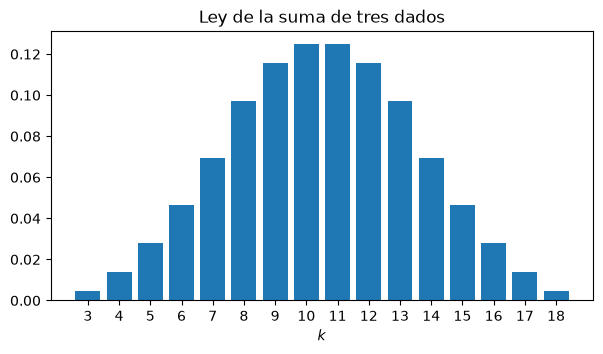

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(ley["k"], ley["P(S=k)"].astype(float))
ax.set_xticks(ley["k"])
ax.set_xlabel("$k$")
ax.set_title("Ley de la suma de tres dados")
plt.show()